# GPR uncertainty, robustness, and patient-entry structure

This notebook runs four Gaussian process regression follow-ups: kernel and split stability, a Student-t-inspired robust fit, a heteroscedastic noise sensitivity analysis, and a patient-entry bag kernel. It uses the same patient-level target and spectral data as notebook 03. The detailed methods, results, caveats, and conclusions are in [`04_gpr_uncertainty_tests.md`](04_gpr_uncertainty_tests.md).

The observations and CV split unit are patients. Regression forecast metrics are primary; binary separation metrics are secondary. The regression-derived threshold exceedance is not a calibrated class probability.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

repo_root = Path.cwd()
if not (repo_root / 'data' / 'preprocessed.npy').exists():
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root / 'src'))
from glioma_raman_gp_regression.gpr_followup import load_patient_data, run_all, print_results

data = load_patient_data(repo_root)
patient_table = pd.DataFrame({
    'patient_id': data['patient_ids'],
    'target': data['y'],
    'entry_count': data['entry_counts'],
})
print(f"Patients: {len(data['patient_ids'])}; entries: {data['entry_counts'].sum()}; channels: {data['channel_count']}")
print('Patients by target (0 = mutant, 1 = wildtype):', patient_table.groupby('target').size().to_dict())
print('Patients with multiple entries:', int((data['entry_counts'] > 1).sum()))

Patients: 46; entries: 59; channels: 1167
Patients by target (0 = mutant, 1 = wildtype): {0: 21, 1: 25}
Patients with multiple entries: 9


## Run the patient-level experiments

Every test uses five patient-stratified folds for seeds 42, 101, and 202. PCA and scaling are fit inside each training fold. The stability sweep gives each GPR two optimizer restarts and records kernel-bound hits. The other comparisons use PCA 8 as a fixed representation carried forward from notebook 03.

In [2]:
results = run_all(data)
print_results(results)

Repeated patient-level GPR stability (mean and SD across split seeds):
                method  rmse_mean  rmse_std  mae_mean  mae_std  normal_nlpd_mean  normal_nlpd_std  coverage_90_mean  coverage_90_std  width_90_mean  width_90_std  accuracy_at_0_5_mean  accuracy_at_0_5_std  balanced_accuracy_at_0_5_mean  balanced_accuracy_at_0_5_std  roc_auc_mean  roc_auc_std
      PCA 12 + RBF ARD      0.442     0.016     0.357    0.009             1.909            1.371             0.748            0.024          1.049         0.057                 0.682                0.034                          0.670                         0.033         0.764        0.032
PCA 12 + RBF isotropic      0.447     0.011     0.378    0.006             0.723            0.139             0.870            0.040          1.407         0.012                 0.651                0.043                          0.638                         0.045         0.753        0.043
      PCA 20 + RBF ARD      0.449     0.065     0.

## Compare regression quality and separation

RMSE and AUC are plotted as a compact summary; lower RMSE and higher AUC are preferred. The reported standard deviations are across the three split seeds and are descriptive, not confidence intervals. See the companion report for interval coverage, widths, NLPD, per-seed results, and interpretation.

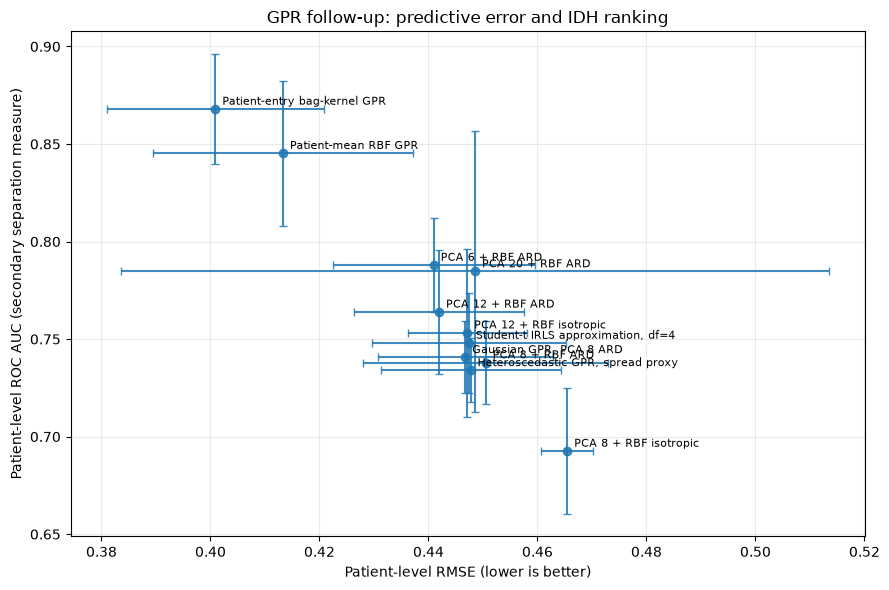

In [3]:
stability = results['stability']['summary'].copy()
noise = results['noise_robustness']['gaussian_summary'].copy()
student = results['noise_robustness']['student_t_summary'].copy()
bag = results['patient_bag']['summary'].copy()
comparison = pd.concat([stability, noise, student, bag], ignore_index=True)
fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(
    comparison['rmse_mean'], comparison['roc_auc_mean'],
    xerr=comparison['rmse_std'], yerr=comparison['roc_auc_std'],
    fmt='o', capsize=3, alpha=0.85,
)
for _, row in comparison.iterrows():
    ax.annotate(row['method'], (row['rmse_mean'], row['roc_auc_mean']), xytext=(5, 3), textcoords='offset points', fontsize=8)
ax.set_xlabel('Patient-level RMSE (lower is better)')
ax.set_ylabel('Patient-level ROC AUC (secondary separation measure)')
ax.set_title('GPR follow-up: predictive error and IDH ranking')
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Interpretation notes

The Student-t cell implements an iterative reweighting approximation rather than exact non-Gaussian GP inference. The noise sensitivity cell uses within-patient spectral spread as a proxy; the input does not contain technical replicate noise or QC metadata. The patient-entry kernel averages pairwise entry similarities while retaining one target and one vote per patient. These limitations are described alongside the results in the companion Markdown report.